In [1]:
# Standard Python modules
import os, sys
import glob
import numpy as np
import pandas as pd
import xarray as xr

# plot styles/formatting
import seaborn as sns
import cmocean.cm as cmo
import cmocean

# matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import AxesGrid
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from matplotlib.colorbar import Colorbar # different way to handle colorbar
from matplotlib.colorbar import ColorbarBase
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from matplotlib.projections import get_projection_class

sys.path.append('../modules')
from timeseries import select_months
import globalvars

In [2]:
path_to_data = globalvars.path_to_data
path_to_out  = '../out/'       # output files (numerical results, intermediate datafiles) -- read & write
path_to_figs = '../figs/'      # figures

In [3]:
df1 = pd.read_csv(path_to_out+'events_box-whisker.csv')
# df1.loc[df1["AR_index"] == 5.5, "AR_index"] = 5
df2 = pd.read_csv(path_to_out+'non-event_box-whisker.csv')
# df2.loc[df2["AR_index"] == 5.5, "AR_index"] = 5
df_lst = [df1, df2]

In [4]:
for i, df in enumerate(df_lst):
    ssn = 'all'
    df = df.set_index(pd.to_datetime(df['impact_date']))
    if ssn == 'DJF':
        df = select_months(df, 12, 2)
    elif ssn == 'cool-season':
        df = select_months(df, 10, 5)
    else:
        df = df
    df
    df = df.reset_index(drop=True)
    
    F_lst = np.arange(24, 168+24, 24)
    varlst = ['IVT', 'Z0', 'UV', 'QPF', 'AR_index']
    for j, F in enumerate(F_lst):
        print('F = {0}'.format(F))
        idx = (df.F == F)
        tmp = df.loc[idx]
        tmp = tmp.drop(columns=["impact_date", "init_date", "F"])
        print(tmp.describe())

F = 24
             IVT         Z0         UV        QPF   AR_index
count  26.000000  26.000000  26.000000  26.000000  26.000000
mean   98.615385   9.500000  98.538462  98.769231   3.480769
std     0.697247  27.064737   1.580652   0.587040   0.574121
min    97.000000   0.000000  91.000000  97.000000   2.000000
25%    98.250000   0.000000  99.000000  99.000000   3.000000
50%    99.000000   0.000000  99.000000  99.000000   3.500000
75%    99.000000   0.000000  99.000000  99.000000   4.000000
max    99.000000  97.000000  99.000000  99.000000   4.000000
F = 48
             IVT         Z0         UV        QPF   AR_index
count  26.000000  26.000000  26.000000  26.000000  26.000000
mean   98.269231  12.346154  98.500000  98.692308   3.403846
std     1.686599  29.750889   1.272792   0.679366   0.678516
min    91.000000   0.000000  94.000000  97.000000   1.500000
25%    98.000000   0.000000  99.000000  99.000000   3.000000
50%    99.000000   0.000000  99.000000  99.000000   3.500000
75%    99.

In [5]:
def add_box_whisker_plots(fig, df, col, letter_lst):
    #######################
    ### BOX AND WHISKER ###
    #######################
    varname_lst = ['IVT', 'Z0', 'UV', 'QPF', 'AR_index']
    color_lst = ['#54B36D', '#FC5F3F', '#9956AD', '#2171b5', '#F5F0E6']
    row_lst = np.arange(0, 6)
    for i, varname in enumerate(varname_lst):
        ax = fig.add_subplot(gs[row_lst[i], col])
        PROPS = {'boxprops':{'facecolor':color_lst[i], 'edgecolor':'k'},
                 'medianprops':{"color": "k"},
                 'whiskerprops':{"color": "k"},
                 'capprops':{"color": "k"},
                 'flierprops':{"marker": "x"},
                 'meanprops':{'c':'k', 'lw':1},
                 'bootstrap': 5000}
        
        ax = sns.boxplot(y=varname, x="F", data=df, 
                            whis=[0, 100],
                        order=np.arange(24, 8*24, 24),
                        meanline=True, showmeans=True, 
                        notch=False, showcaps=True,
                        linewidth=0.75, ax=ax,
                        **PROPS)
        
        #  set the ticks first
        if varname == 'AR_index':
            ax.set_ylim(0., 6)
            ax.set_yticks(np.arange(0., 6, 1))
        else:
            ax.set_ylim(74, 105)
            # Set ticks 
            ax.set_yticks(np.arange(75, 101, 5)) # major ticks 
            ax.set_yticks(np.arange(75, 101, 1), minor=True) # minor ticks
    
            for k in [0, 3, 4, 5]:
                ax.get_yticklabels()[k].set_color("grey")
    
            # Add custom vertical lines (e.g., at specific data points)
            custom_y_positions = [75, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]
            for y_pos in custom_y_positions:
                ax.axhline(y=y_pos, xmin=-0.01, xmax=0.01, color='grey', linestyle='-', linewidth=1.)
            
        if col == 0:
            if i <= 3:
                ax.set_ylabel('{0}'.format(varname))
        
            else:
                ax.set_ylabel('AR Hazard Index')
        else:
            ax.set_ylabel('')
        if row_lst[i] == 5:
            ax.set_xlabel('Lead (hours)')
        else:
            ax.set_xlabel('')
        ax.text(0.02, 0.98, f'({letter_lst[i]})', ha='left', va='top', 
                # backgroundcolor='white',
                transform=ax.transAxes, fontsize=9., zorder=110)

    return fig

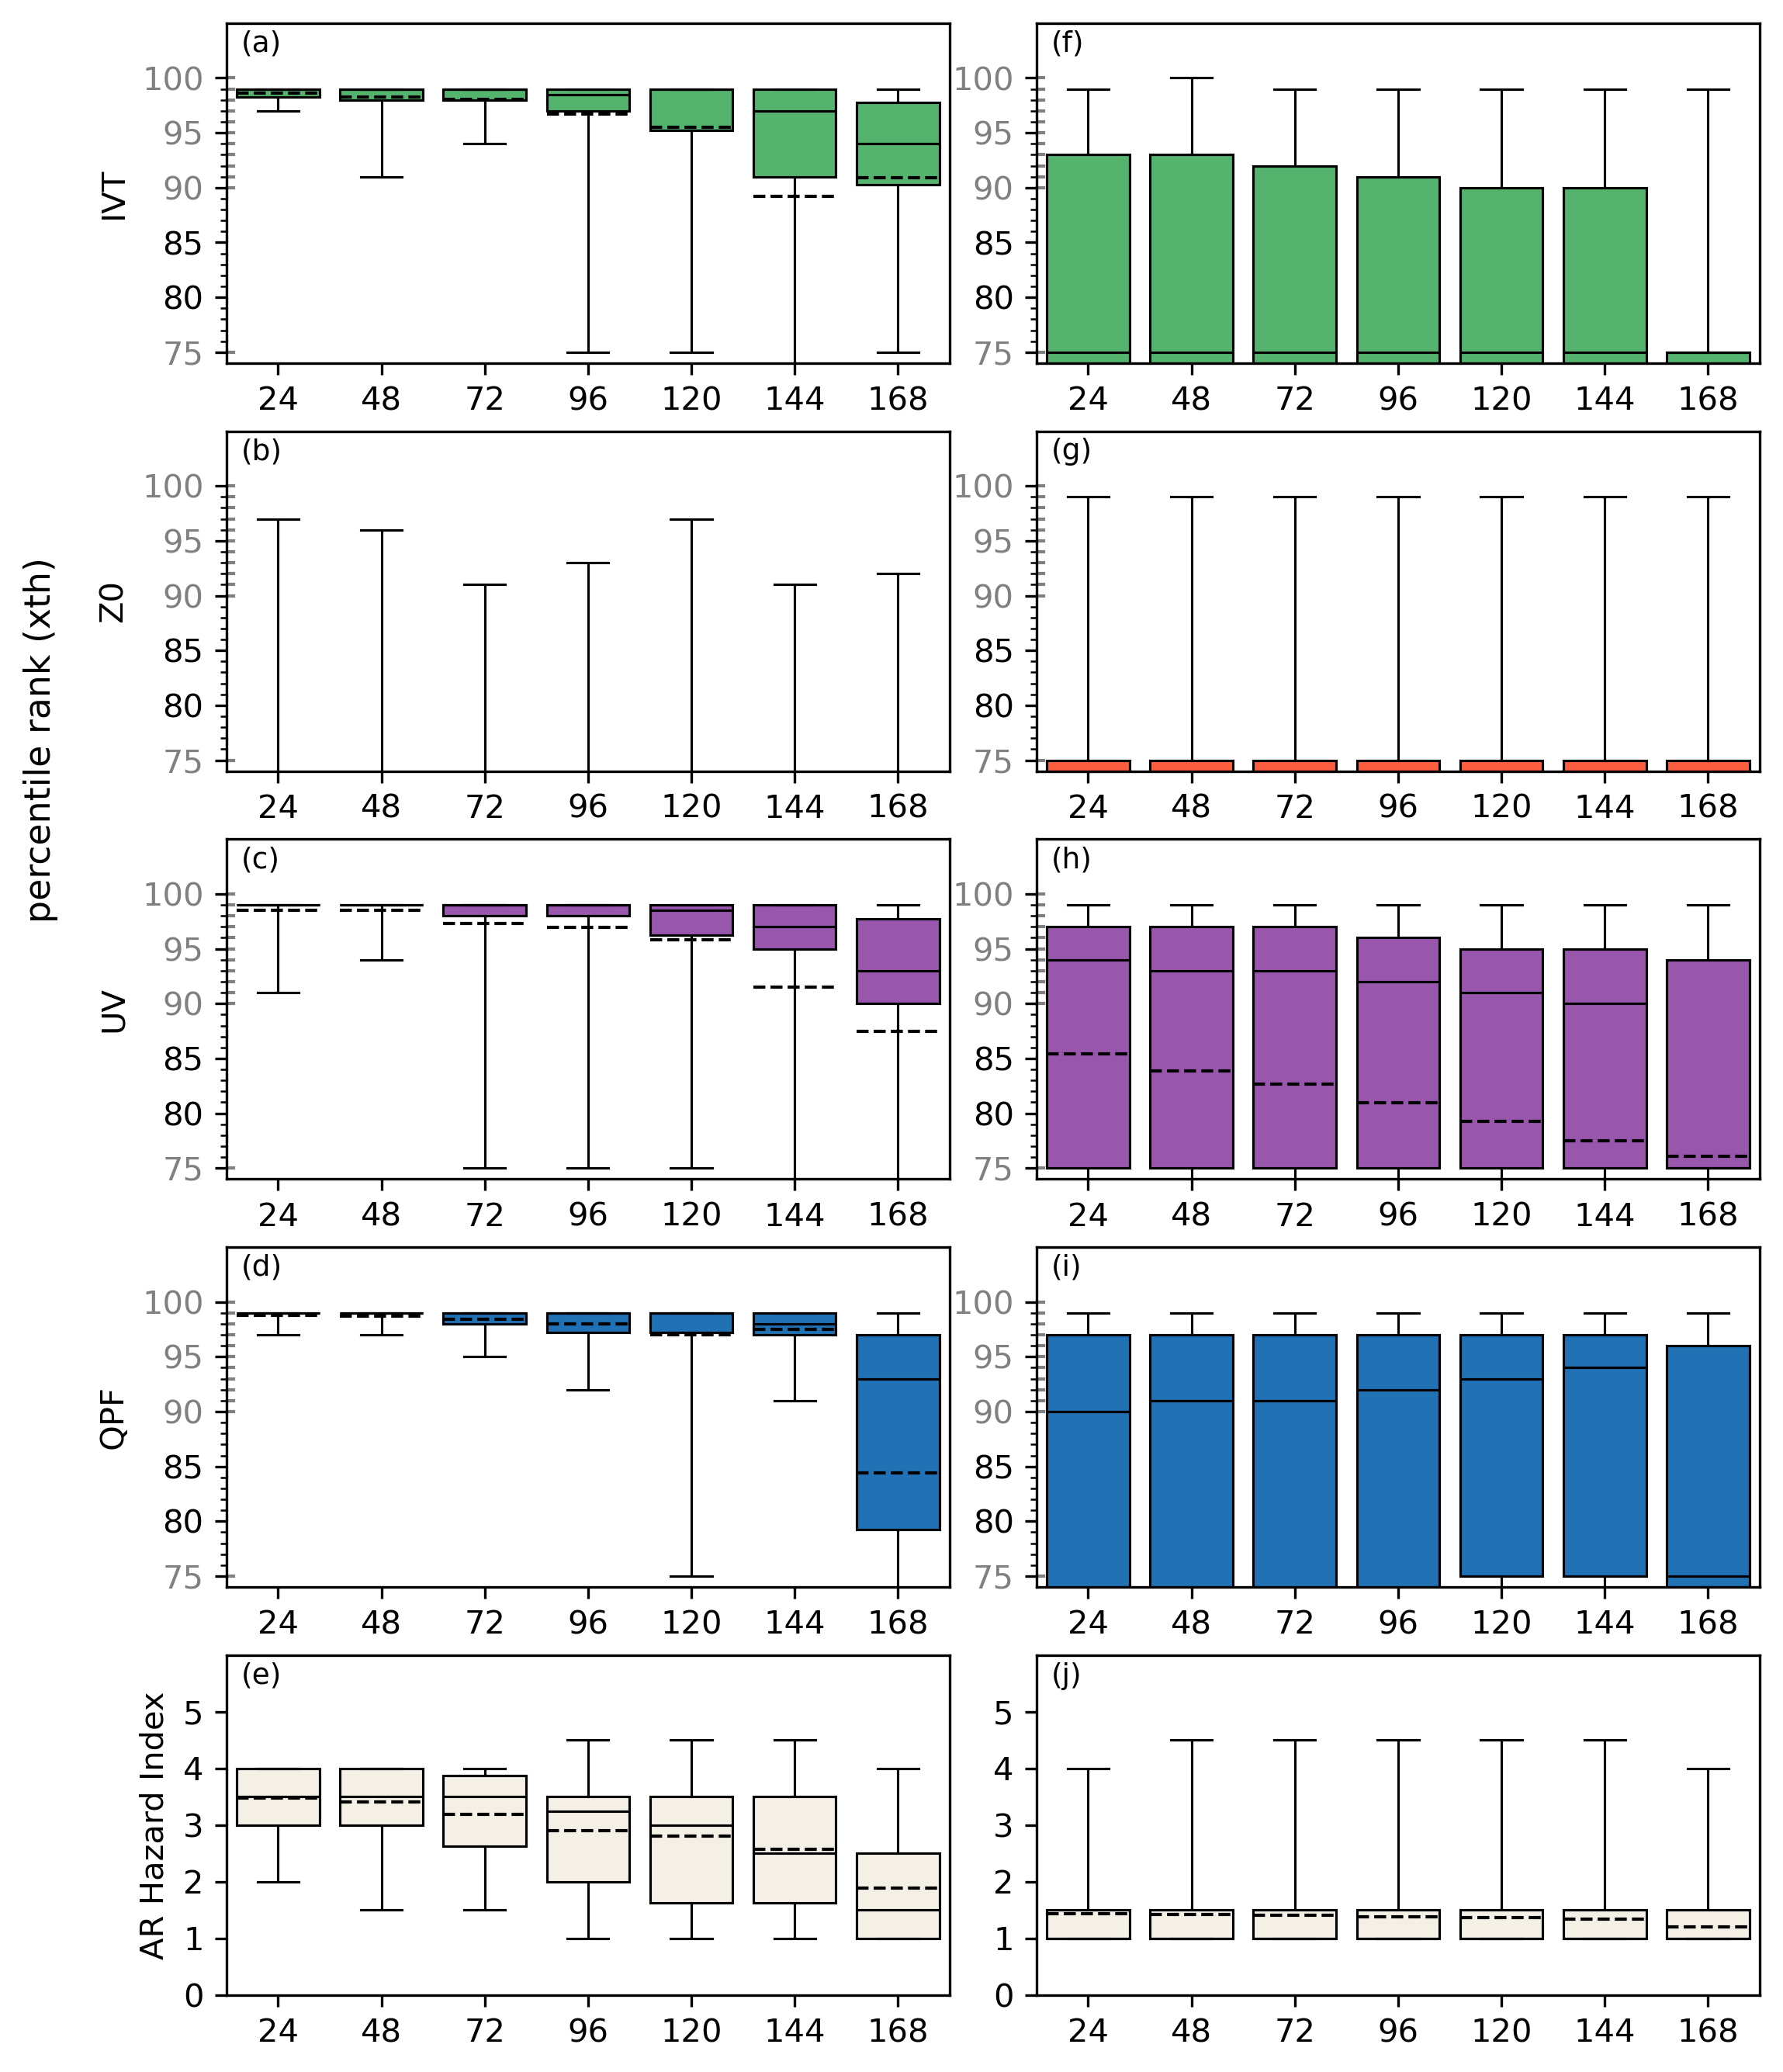

In [6]:
# Create figure
fig = plt.figure(figsize=(8.5, 11))
fig.dpi = 300
fname = path_to_figs + 'box_whisker_{0}'.format(ssn)
fmt = 'png'

nrows = 5
ncols = 2

## Use gridspec to set up a plot with a series of subplots that is
## n-rows by n-columns
gs = GridSpec(nrows, ncols, height_ratios=[1, 1, 1, 1, 1], width_ratios = [1, 1], wspace=0.12, hspace=0.2)
## use gs[rows index, columns index] to access grids

col_lst = [0, 1]
letters = [['a', 'b', 'c', 'd', 'e'], ['f', 'g', 'h', 'i', 'j']]
## add box and whiskers
for i, (df, col, letter_lst) in enumerate(zip(df_lst, col_lst, letters)):
    fig = add_box_whisker_plots(fig, df, col, letter_lst)

## add horizontal text that says 'percentile rank (xth)'
## centered for top four plots
fig.text(0.04, 0.6, 'percentile rank (xth)', va='bottom', ha='center',
                rotation='vertical', rotation_mode='anchor', fontsize=11)

fig.savefig('%s.%s' %(fname, fmt), bbox_inches='tight', dpi=fig.dpi, transparent=True)

# Show
plt.show()

In [18]:

df

,impact_date,init_date,model_name,F,IVT,Z0,UV,QPF,AR_index,n_extreme
0,2000-02-13,2000-02-12,GEFSv12_reforecast,24,99.0,0.0,98.0,98.0,2.5,3
1,2000-02-13,2000-02-11,GEFSv12_reforecast,48,98.0,0.0,95.0,98.0,2.0,3
2,2000-02-13,2000-02-10,GEFSv12_reforecast,72,98.0,0.0,98.0,98.0,2.5,3
3,2000-02-13,2000-02-09,GEFSv12_reforecast,96,92.0,0.0,93.0,96.0,1.0,1
4,2000-02-13,2000-02-08,GEFSv12_reforecast,120,75.0,0.0,75.0,96.0,1.0,1
...,...,...,...,...,...,...,...,...,...,...
219,2024-12-14,2024-12-11,GEFS_archive,72,NaN,NaN,NaN,NaN,NaN,0
220,2024-12-14,2024-12-10,GEFS_archive,96,NaN,NaN,NaN,NaN,NaN,0
221,2024-12-14,2024-12-09,GEFS_archive,120,NaN,NaN,NaN,NaN,NaN,0
222,2024-12-14,2024-12-08,GEFS_archive,144,NaN,NaN,NaN,NaN,NaN,0


<Axes: xlabel='F', ylabel='n_extreme'>

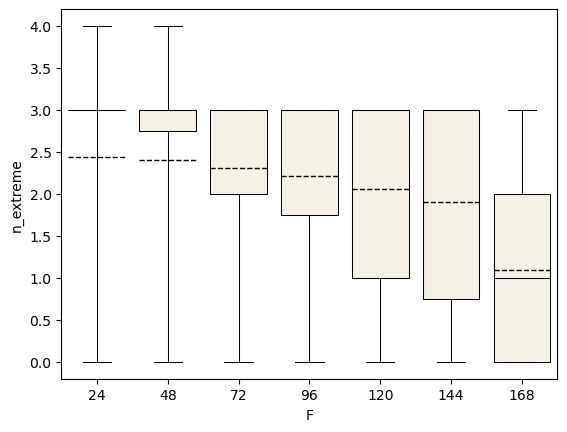

In [19]:
vars_use = ['IVT', 'UV', 'QPF', 'Z0']  # exclude Z0 if desired
threshold = 95

df['n_extreme'] = (df[vars_use] >= threshold).sum(axis=1)

PROPS = {'boxprops':{'facecolor':'#F5F0E6', 'edgecolor':'k'},
                 'medianprops':{"color": "k"},
                 'whiskerprops':{"color": "k"},
                 'capprops':{"color": "k"},
                 'flierprops':{"marker": "x"},
                 'meanprops':{'c':'k', 'lw':1},
                 'bootstrap': 5000}
        
sns.boxplot(y="n_extreme", x="F", data=df, 
                whis=[0, 100],
                order=np.arange(24, 8*24, 24),
                meanline=True, showmeans=True, 
                notch=False, showcaps=True,
                linewidth=0.75,
                **PROPS)

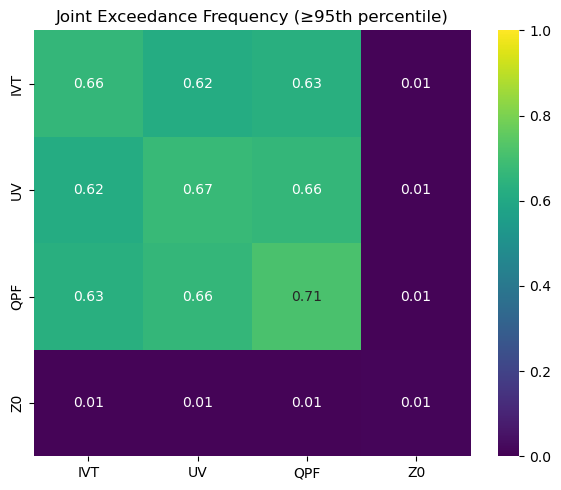

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

vars_use = ['IVT', 'UV', 'QPF', 'Z0']
threshold = 95

def compute_joint_exceedance(df, vars_use, threshold):
    n = len(vars_use)
    mat = pd.DataFrame(np.zeros((n, n)), index=vars_use, columns=vars_use)

    for i, v1 in enumerate(vars_use):
        for j, v2 in enumerate(vars_use):
            both_extreme = ((df[v1] >= threshold) & (df[v2] >= threshold)).mean()
            mat.loc[v1, v2] = both_extreme

    return mat

joint_mat = compute_joint_exceedance(df, vars_use, threshold)

plt.figure(figsize=(6,5))
sns.heatmap(joint_mat, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title(f"Joint Exceedance Frequency (≥{threshold}th percentile)")
plt.tight_layout()
plt.show()

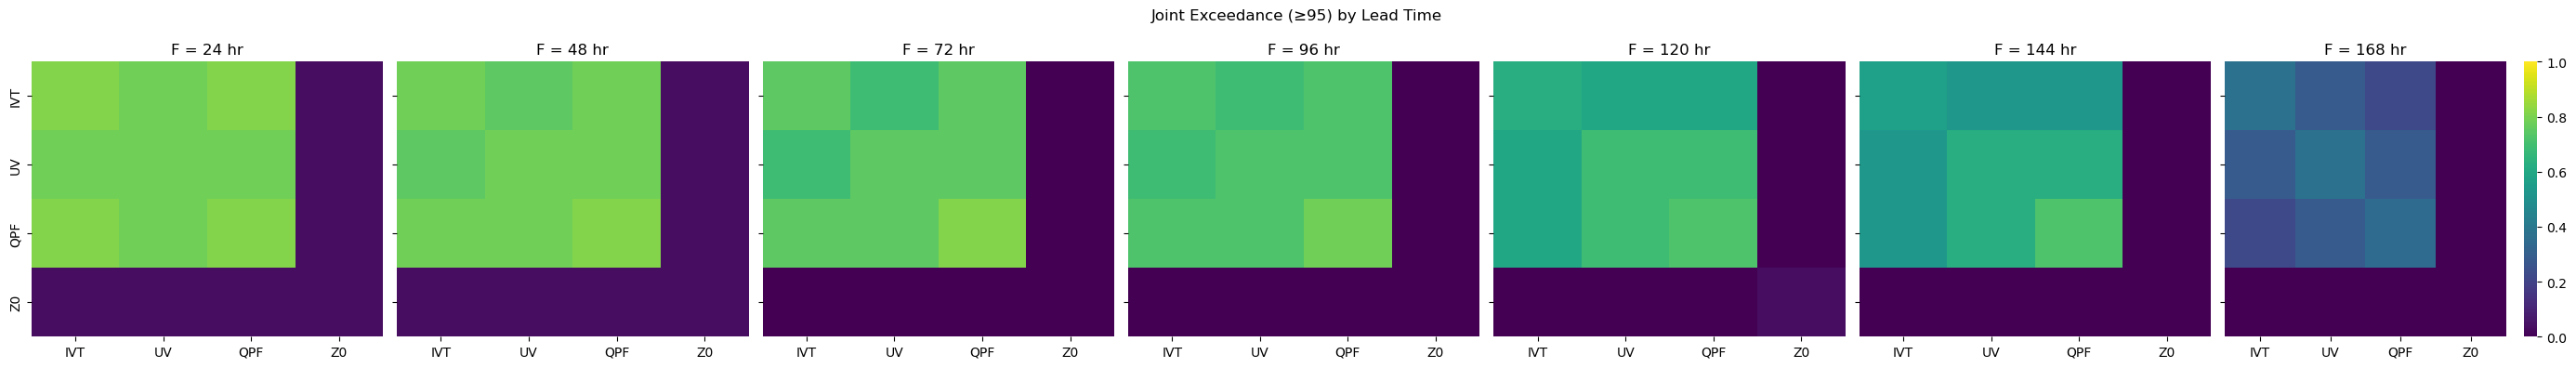

In [22]:
lead_times = sorted(df['F'].unique())

fig, axes = plt.subplots(1, len(lead_times), figsize=(4*len(lead_times), 4), sharey=True)

for ax, lt in zip(axes, lead_times):
    sub = df[df['F'] == lt]
    mat = compute_joint_exceedance(sub, vars_use, threshold)
    
    sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap="viridis", cbar=(ax==axes[-1]))
    ax.set_title(f"F = {lt} hr")

plt.suptitle(f"Joint Exceedance (≥{threshold}) by Lead Time")
plt.tight_layout()
plt.show()

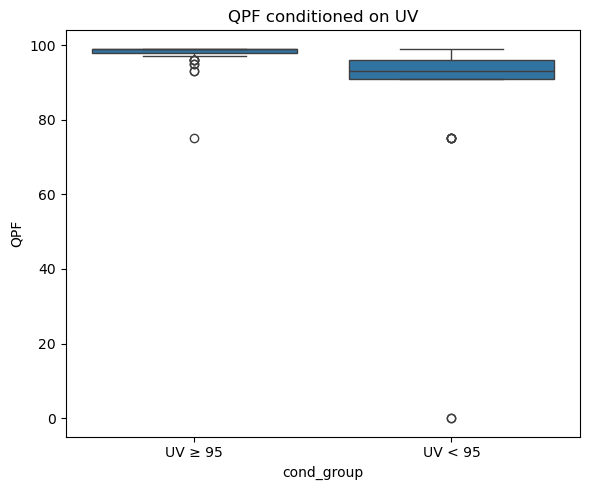

In [28]:
cond_var = 'UV'
target_var = 'QPF'

df['cond_group'] = np.where(df[cond_var] >= threshold,
                           f'{cond_var} ≥ {threshold}',
                           f'{cond_var} < {threshold}')

plt.figure(figsize=(6,5))
sns.boxplot(data=df, x='cond_group', y=target_var)
plt.title(f"{target_var} conditioned on {cond_var}")
plt.tight_layout()
plt.show()

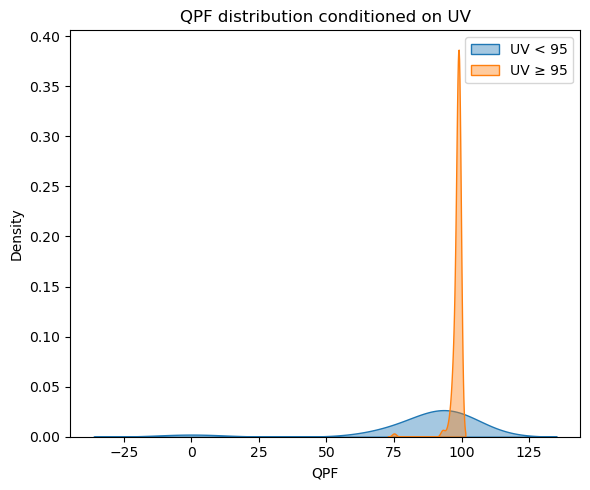

In [29]:
plt.figure(figsize=(6,5))

for label, subset in df.groupby('cond_group'):
    sns.kdeplot(subset[target_var], label=label, fill=True, common_norm=False, alpha=0.4)

plt.title(f"{target_var} distribution conditioned on {cond_var}")
plt.legend()
plt.tight_layout()
plt.show()

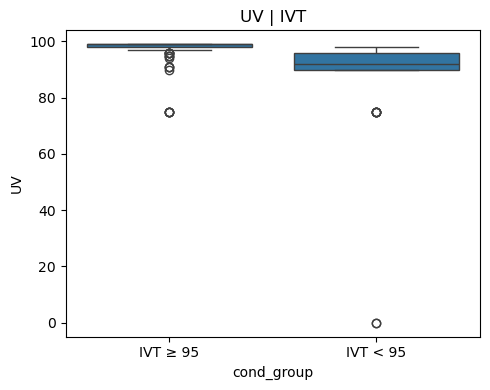

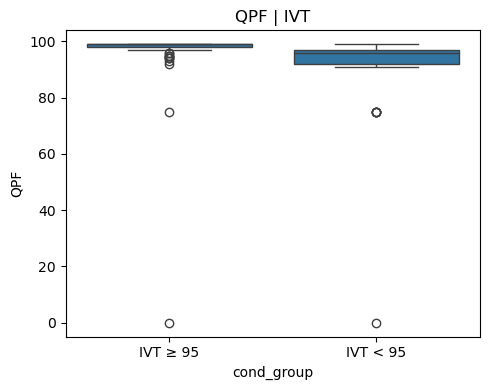

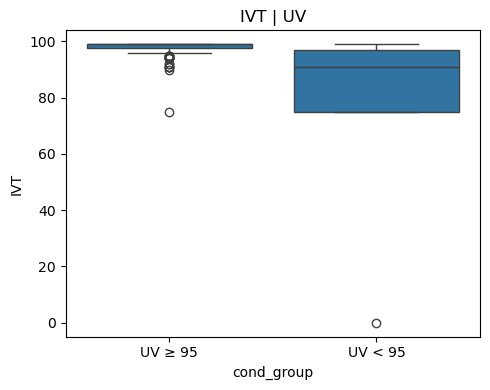

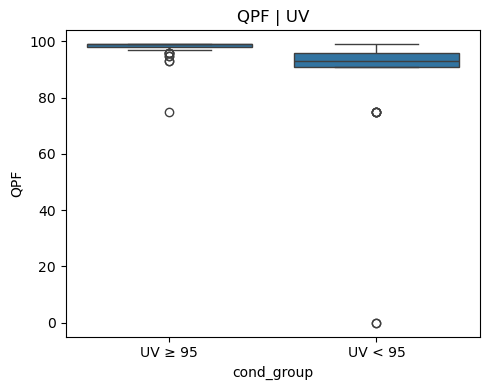

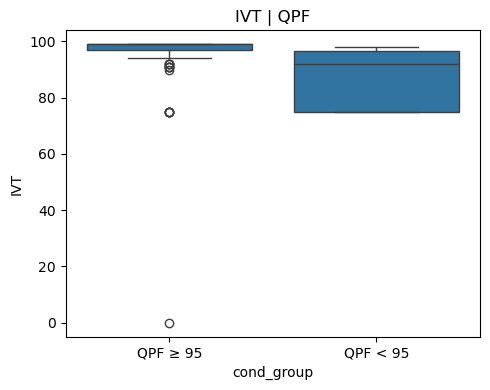

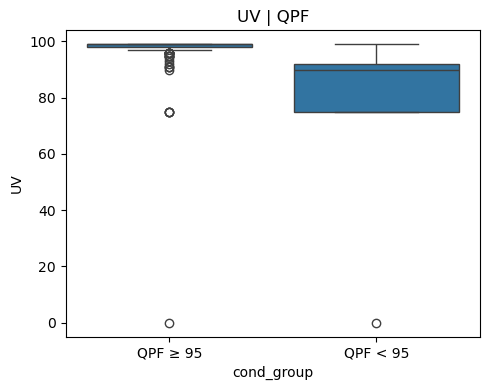

In [25]:
import itertools

vars_use = ['IVT', 'UV', 'QPF']  # probably exclude Z0 here

pairs = list(itertools.permutations(vars_use, 2))

for cond_var, target_var in pairs:
    df['cond_group'] = np.where(df[cond_var] >= threshold,
                               f'{cond_var} ≥ {threshold}',
                               f'{cond_var} < {threshold}')
    
    plt.figure(figsize=(5,4))
    sns.boxplot(data=df, x='cond_group', y=target_var)
    plt.title(f"{target_var} | {cond_var}")
    plt.tight_layout()
    plt.show()

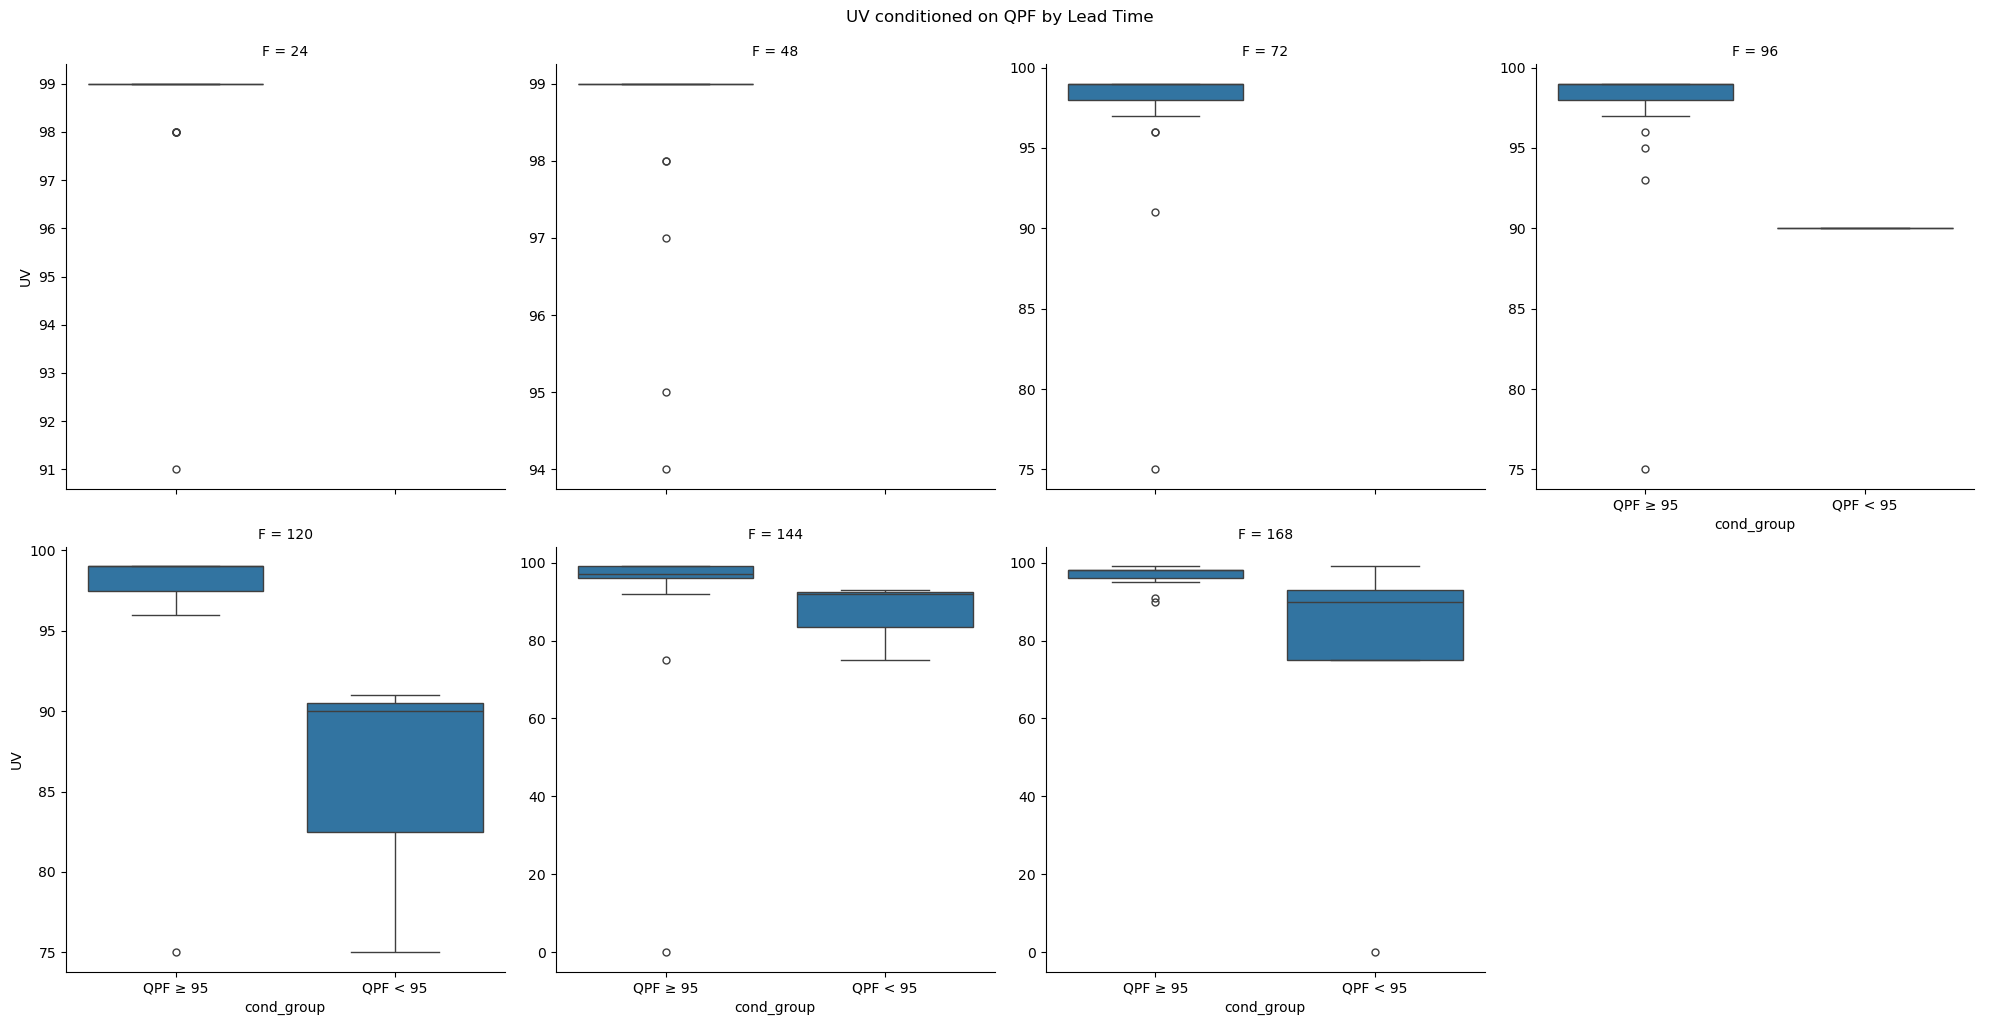

In [27]:
g = sns.catplot(
    data=df,
    x='cond_group',
    y=target_var,
    col='F',
    kind='box',
    col_wrap=4,
    sharey=False
)

g.fig.suptitle(f"{target_var} conditioned on {cond_var} by Lead Time", y=1.02)
plt.show()